# Phase 2 Housing Aggregation — ZIP Code × Year

**Contributor:** Mohamed Walid  
**Source:** NYC DOB NOW Build Job Application Filings, cleaned by the Phase 1 housing pipeline  
**Analysis window:** 2022-01-01 through 2026-10-31

This notebook converts filing-level housing data into one record per ZIP code and year. The aggregation is required before integration with collision data because joining individual filings directly to individual collisions would create a many-to-many expansion and distort both housing and crash counts.

Construction activity is measured using initial (`I1`) filings only. Each retained initial filing represents one distinct construction job within the analysis window.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pandas.api.types import is_bool_dtype, is_integer_dtype, is_string_dtype

INPUT = Path("data/housing_step2.csv.gz")
OUTPUT = Path("data/housing_zip_year.csv.gz")
SCOPE_START = pd.Timestamp("2022-01-01")
SCOPE_END = pd.Timestamp("2026-11-01")

if not INPUT.exists():
    raise FileNotFoundError(
        "Missing data/housing_step2.csv.gz. "
        "Run the verified Phase 1 housing pipeline first."
    )

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.2f}".format)

## Input validation

The Phase 1 output is loaded with explicit types for integration keys and identifiers. The checks below verify its required schema, agreed date window, ZIP format, filing uniqueness, and consistency between the `is_initial_filing` flag and the `-I1` filing-number suffix. Invalid records are not silently corrected or removed.

In [2]:
df = pd.read_csv(
    INPUT,
    compression="gzip",
    dtype={
        "job_filing_number": "string",
        "job_id": "string",
        "zip_code": "string",
        "borough": "string",
        "job_type": "string",
        "year": "Int64",
        "is_initial_filing": "boolean",
    },
    low_memory=False,
)

required_columns = {
    "job_filing_number",
    "job_id",
    "is_initial_filing",
    "job_type",
    "filing_date",
    "year",
    "zip_code",
    "borough",
    "proposed_dwelling_units",
}
missing_columns = required_columns - set(df.columns)
assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"

filing_dates = pd.to_datetime(df["filing_date"], format="mixed", errors="coerce")
assert filing_dates.notna().all(), "Unparseable filing dates found."
assert (filing_dates >= SCOPE_START).all(), "Dates before 2022-01-01 found."
assert (filing_dates < SCOPE_END).all(), "Dates on/after 2026-11-01 found."
assert df["year"].notna().all(), "Missing year values found."
assert df["year"].between(2022, 2026).all(), "Years outside 2022–2026 found."
assert (df["year"].astype("int64") == filing_dates.dt.year).all(), (
    "Derived years do not match filing dates."
)

assert df["zip_code"].notna().all(), "Missing ZIP codes found."
assert df["zip_code"].str.fullmatch(r"\d{5}").all(), "Invalid ZIP codes found."
assert df["job_id"].notna().all(), "Missing job IDs found."
assert df["job_filing_number"].notna().all(), "Missing filing identifiers found."
assert not df["job_filing_number"].duplicated().any(), (
    "Duplicate filing identifiers found."
)
assert df["is_initial_filing"].notna().all(), (
    "Missing initial-filing flags found."
)

expected_i1 = df["job_filing_number"].str.endswith("-I1")
assert (df["is_initial_filing"].astype(bool) == expected_i1).all(), (
    "Initial-filing flags disagree with filing-number suffixes."
)

input_summary = pd.Series(
    {
        "Filing rows": len(df),
        "Columns": len(df.columns),
        "Unique jobs": df["job_id"].nunique(),
        "Unique ZIP codes": df["zip_code"].nunique(),
        "Earliest filing date": filing_dates.min().date(),
        "Latest filing date": filing_dates.max().date(),
        "Duplicate filing identifiers": int(df["job_filing_number"].duplicated().sum()),
    },
    name="Validated value",
)
display(input_summary.to_frame())
print("Input validation: PASS")

,Validated value
Filing rows,730450
Columns,34
Unique jobs,404592
Unique ZIP codes,224
Earliest filing date,2022-01-01
Latest filing date,2026-10-31
Duplicate filing identifiers,0


Input validation: PASS


## I1 selection and reconciliation

The team definition counts construction jobs from `I1` initial filings only—not from every filing. Later filings for the same job can represent amendments or follow-up activity and would otherwise cause repeated job counts.

Jobs without an I1 filing inside the window are excluded because their initial filing may predate 2022. Counting a later filing would incorrectly attribute an older project to this analysis period. The excluded count shown below is a snapshot result, not a permanent constant.

If duplicate I1 job IDs ever appear, the documented deterministic rule retains the earliest filing date and then the alphabetically smallest filing number. Any removal is printed rather than performed silently.

In [3]:
i1 = df.loc[df["is_initial_filing"].eq(True)].copy()
i1["_filing_date"] = filing_dates.loc[i1.index]

total_filings = len(df)
total_jobs = df["job_id"].nunique()
i1_rows_before_resolution = len(i1)
unique_i1_jobs_before_resolution = i1["job_id"].nunique()
jobs_without_i1 = total_jobs - unique_i1_jobs_before_resolution

duplicate_i1_mask = i1["job_id"].duplicated(keep=False)
duplicate_i1_job_ids = i1.loc[duplicate_i1_mask, "job_id"].nunique()
removed_duplicate_i1_rows = 0

if duplicate_i1_job_ids:
    print(f"Duplicate I1 job IDs requiring deterministic resolution: {duplicate_i1_job_ids:,}")
    display(
        i1.loc[
            duplicate_i1_mask,
            ["job_id", "job_filing_number", "filing_date", "zip_code", "year"],
        ]
        .sort_values(["job_id", "_filing_date", "job_filing_number"])
        .head(25)
    )
    before = len(i1)
    i1 = (
        i1.sort_values(
            ["_filing_date", "job_filing_number"],
            kind="stable",
        )
        .drop_duplicates("job_id", keep="first")
        .copy()
    )
    removed_duplicate_i1_rows = before - len(i1)
    print(f"Duplicate I1 rows removed: {removed_duplicate_i1_rows:,}")
else:
    print("Duplicate I1 job IDs: 0; no tie-breaking was needed.")

assert not i1["job_id"].duplicated().any(), "Duplicate I1 job IDs remain."

reconciliation_snapshot = pd.Series(
    {
        "Total filing records": total_filings,
        "Total unique jobs": total_jobs,
        "I1 rows before duplicate resolution": i1_rows_before_resolution,
        "Unique I1 jobs": unique_i1_jobs_before_resolution,
        "Jobs without I1 in the analysis window": jobs_without_i1,
        "Duplicate I1 job IDs": duplicate_i1_job_ids,
        "Retained I1 jobs": i1["job_id"].nunique(),
    },
    name="Count",
)
display(reconciliation_snapshot.to_frame())

display(
    Markdown(
        f"**Current snapshot finding:** {jobs_without_i1:,} unique jobs have no I1 "
        "filing within the analysis window and are excluded from newly started "
        "construction-job counts."
    )
)

Duplicate I1 job IDs: 0; no tie-breaking was needed.


,Count
Total filing records,730450
Total unique jobs,404592
I1 rows before duplicate resolution,375293
Unique I1 jobs,375293
Jobs without I1 in the analysis window,29299
Duplicate I1 job IDs,0
Retained I1 jobs,375293


**Current snapshot finding:** 29,299 unique jobs have no I1 filing within the analysis window and are excluded from newly started construction-job counts.

## Standardizing aggregation fields

### Borough assignment

Borough labels are stripped and converted to Title Case before frequency calculation. Each ZIP receives one borough based on the most frequent non-missing label across all its retained I1 records—not separately by year. Frequency ties are resolved alphabetically. The notebook fails rather than inventing a borough when a ZIP has no usable borough value.

### Job types

The specialized counts use the exact categories `New Building`, `Alteration`, and `Full Demolition`. Other categories remain part of the overall housing-job count but not the three specialized counts.

### Missing-value handling

For I1 New Building records only, missing proposed dwelling units are treated as zero. Non-numeric, fractional, or negative eligible values cause validation to fail; values are never silently rounded or made nonnegative.

In [4]:
assert i1["zip_code"].notna().all(), "I1 rows contain missing ZIP codes."
assert i1["zip_code"].str.fullmatch(r"\d{5}").all(), "I1 rows contain invalid ZIPs."
assert i1["year"].notna().all(), "I1 rows contain missing years."
assert i1["year"].between(2022, 2026).all(), "I1 rows contain invalid years."

i1["borough"] = (
    i1["borough"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace("", pd.NA)
)

borough_frequencies = (
    i1.dropna(subset=["borough"])
    .groupby(["zip_code", "borough"], observed=True)
    .size()
    .rename("frequency")
    .reset_index()
    .sort_values(
        ["zip_code", "frequency", "borough"],
        ascending=[True, False, True],
        kind="stable",
    )
)
zip_borough = (
    borough_frequencies.drop_duplicates("zip_code", keep="first")
    .set_index("zip_code")["borough"]
)
zips_without_borough = sorted(set(i1["zip_code"]) - set(zip_borough.index))
if zips_without_borough:
    print("ZIP codes without a usable borough:", zips_without_borough)
assert not zips_without_borough, (
    "Complete borough assignment is impossible; output requires review."
)

print("I1 job-type distribution:")
display(i1["job_type"].value_counts(dropna=False).rename("I1 jobs").to_frame())

i1["_is_new_building"] = i1["job_type"].eq("New Building")
i1["_is_alteration"] = i1["job_type"].eq("Alteration")
i1["_is_demolition"] = i1["job_type"].eq("Full Demolition")

raw_dwelling_units = i1["proposed_dwelling_units"]
numeric_dwelling_units = pd.to_numeric(raw_dwelling_units, errors="coerce")
eligible = i1["_is_new_building"]

invalid_non_numeric = eligible & raw_dwelling_units.notna() & numeric_dwelling_units.isna()
eligible_numeric = numeric_dwelling_units.loc[eligible & numeric_dwelling_units.notna()]
fractional_eligible = int((eligible_numeric.mod(1) != 0).sum())
negative_eligible = int((eligible_numeric < 0).sum())
missing_dwelling_units_treated_as_zero = int(
    (eligible & numeric_dwelling_units.isna()).sum()
)

assert not invalid_non_numeric.any(), "Non-numeric New Building dwelling units found."
assert fractional_eligible == 0, "Fractional New Building dwelling units found."
assert negative_eligible == 0, "Negative New Building dwelling units found."

i1["_new_building_dwelling_units"] = 0
i1.loc[eligible, "_new_building_dwelling_units"] = (
    numeric_dwelling_units.loc[eligible].fillna(0).astype("int64")
)
i1["_new_building_dwelling_units"] = i1[
    "_new_building_dwelling_units"
].astype("int64")

display(
    Markdown(
        f"**Actual missing-value result:** {missing_dwelling_units_treated_as_zero:,} "
        "I1 New Building record(s) had missing proposed dwelling units and were "
        "treated as zero for this metric."
    )
)

I1 job-type distribution:


,I1 jobs
job_type,
Alteration,336001
Alteration CO,12613
No Work,10306
New Building,8439
Full Demolition,5423
ALT-CO - New Building with Existing Elements to Remain,2511


**Actual missing-value result:** 0 I1 New Building record(s) had missing proposed dwelling units and were treated as zero for this metric.

## Aggregation method

The output grain is exactly one row per `(zip_code, year)`:

- `housing_job_count`: distinct retained I1 `job_id` values.
- `new_building_count`: distinct I1 jobs with `job_type == "New Building"`.
- `alteration_job_count`: distinct I1 jobs with `job_type == "Alteration"`.
- `demolition_job_count`: distinct I1 jobs with `job_type == "Full Demolition"`.
- `proposed_dwelling_units_new_buildings`: proposed units summed only from I1 New Building records, with documented missing values treated as zero.
- `borough`: ZIP-level majority borough after normalization and alphabetical tie-breaking.
- `is_partial_year`: `True` only for 2026, which covers January through October.

In [5]:
group_keys = ["zip_code", "year"]

housing_jobs = i1.groupby(group_keys, observed=True)["job_id"].nunique()
new_buildings = (
    i1.loc[i1["_is_new_building"]]
    .groupby(group_keys, observed=True)["job_id"]
    .nunique()
)
alterations = (
    i1.loc[i1["_is_alteration"]]
    .groupby(group_keys, observed=True)["job_id"]
    .nunique()
)
demolitions = (
    i1.loc[i1["_is_demolition"]]
    .groupby(group_keys, observed=True)["job_id"]
    .nunique()
)
new_building_units = (
    i1.loc[i1["_is_new_building"]]
    .groupby(group_keys, observed=True)["_new_building_dwelling_units"]
    .sum()
)

aggregated = pd.concat(
    [
        housing_jobs.rename("housing_job_count"),
        new_buildings.rename("new_building_count"),
        alterations.rename("alteration_job_count"),
        demolitions.rename("demolition_job_count"),
        new_building_units.rename("proposed_dwelling_units_new_buildings"),
    ],
    axis=1,
).fillna(0).reset_index()

aggregated["borough"] = aggregated["zip_code"].map(zip_borough)
aggregated["is_partial_year"] = aggregated["year"].eq(2026)

count_columns = [
    "housing_job_count",
    "new_building_count",
    "alteration_job_count",
    "demolition_job_count",
    "proposed_dwelling_units_new_buildings",
]
for column in count_columns:
    aggregated[column] = aggregated[column].astype("int64")

aggregated["zip_code"] = aggregated["zip_code"].astype("string")
aggregated["year"] = aggregated["year"].astype("int64")
aggregated["borough"] = aggregated["borough"].astype("string")
aggregated["is_partial_year"] = aggregated["is_partial_year"].astype("boolean")

output_columns = [
    "zip_code",
    "year",
    "borough",
    "housing_job_count",
    "new_building_count",
    "alteration_job_count",
    "demolition_job_count",
    "proposed_dwelling_units_new_buildings",
    "is_partial_year",
]
aggregated = (
    aggregated[output_columns]
    .sort_values(["zip_code", "year"], kind="stable")
    .reset_index(drop=True)
)

display(aggregated.head())
print(f"Aggregated rows: {len(aggregated):,}")

,zip_code,year,borough,housing_job_count,new_building_count,alteration_job_count,demolition_job_count,proposed_dwelling_units_new_buildings,is_partial_year
0,10000,2022,Manhattan,39,1,29,0,0,False
1,10000,2023,Manhattan,26,0,15,0,0,False
2,10000,2024,Manhattan,19,0,9,0,0,False
3,10000,2025,Manhattan,23,0,11,0,0,False
4,10000,2026,Manhattan,27,0,13,0,0,True


Aggregated rows: 1,104


## Aggregation validation and reconciliation

The following reusable validation checks enforce the exact nine-column schema, unique ZIP-year grain, data types, missing-value rules, nonnegative integer metrics, per-row category bounds, consistent borough labels, and partial-year definition.

Global reconciliation then confirms that every retained I1 job appears in exactly one group and that all category and dwelling-unit totals equal the eligible source records.

In [6]:
def validate_aggregate(frame, label):
    assert list(frame.columns) == output_columns, f"{label}: incorrect columns or order."
    assert len(frame.columns) == 9, f"{label}: expected nine columns."
    assert not frame.duplicated(["zip_code", "year"]).any(), (
        f"{label}: duplicate ZIP-year keys found."
    )
    assert frame["zip_code"].notna().all(), f"{label}: missing ZIP codes."
    assert frame["year"].notna().all(), f"{label}: missing years."
    assert frame["zip_code"].str.fullmatch(r"\d{5}").all(), (
        f"{label}: invalid ZIP format."
    )
    assert frame["year"].between(2022, 2026).all(), f"{label}: invalid years."
    assert is_string_dtype(frame["zip_code"].dtype), f"{label}: ZIP is not string."
    assert is_integer_dtype(frame["year"].dtype), f"{label}: year is not integer."
    assert frame["borough"].notna().all(), f"{label}: unresolved boroughs."
    assert (frame["borough"] == frame["borough"].str.title()).all(), (
        f"{label}: borough labels are not Title Case."
    )
    assert frame.groupby("zip_code", observed=True)["borough"].nunique().le(1).all(), (
        f"{label}: a ZIP has inconsistent boroughs across years."
    )
    assert frame[count_columns].notna().all().all(), f"{label}: missing counts."
    assert all(is_integer_dtype(frame[c].dtype) for c in count_columns), (
        f"{label}: count columns are not integers."
    )
    assert (frame[count_columns] >= 0).all().all(), f"{label}: negative counts."
    assert is_bool_dtype(frame["is_partial_year"].dtype), (
        f"{label}: partial-year flag is not Boolean."
    )
    assert frame["is_partial_year"].notna().all(), (
        f"{label}: missing partial-year flags."
    )
    assert (frame["is_partial_year"].astype(bool) == frame["year"].eq(2026)).all(), (
        f"{label}: partial-year flags are inconsistent."
    )
    for category_column in [
        "new_building_count",
        "alteration_job_count",
        "demolition_job_count",
    ]:
        assert (frame[category_column] <= frame["housing_job_count"]).all(), (
            f"{label}: {category_column} exceeds total jobs."
        )
    assert (
        frame[
            ["new_building_count", "alteration_job_count", "demolition_job_count"]
        ].sum(axis=1)
        <= frame["housing_job_count"]
    ).all(), f"{label}: specialized job counts exceed total jobs."
    print(f"{label}: validation PASS")


validate_aggregate(aggregated, "Pre-export aggregate")

expected_totals = {
    "housing_job_count": int(i1["job_id"].nunique()),
    "new_building_count": int(i1.loc[i1["_is_new_building"], "job_id"].nunique()),
    "alteration_job_count": int(i1.loc[i1["_is_alteration"], "job_id"].nunique()),
    "demolition_job_count": int(i1.loc[i1["_is_demolition"], "job_id"].nunique()),
    "proposed_dwelling_units_new_buildings": int(
        i1.loc[i1["_is_new_building"], "_new_building_dwelling_units"].sum()
    ),
}
actual_totals = {column: int(aggregated[column].sum()) for column in count_columns}

assert actual_totals == expected_totals, (
    f"Metric reconciliation failed: actual={actual_totals}, expected={expected_totals}"
)
assert actual_totals["housing_job_count"] == len(i1), (
    "Not every retained unique I1 job appears in exactly one ZIP-year group."
)

reconciliation_table = pd.DataFrame(
    {"Expected from I1": expected_totals, "Aggregated total": actual_totals}
)
reconciliation_table["Matches"] = (
    reconciliation_table["Expected from I1"]
    == reconciliation_table["Aggregated total"]
)
display(reconciliation_table)

display(
    Markdown(
        "### Actual reconciliation result\n\n"
        f"The final aggregate contains **{actual_totals['housing_job_count']:,}** "
        "housing jobs, exactly matching the retained unique I1 jobs. It includes "
        f"**{actual_totals['new_building_count']:,}** new-building jobs, "
        f"**{actual_totals['alteration_job_count']:,}** alteration jobs, "
        f"**{actual_totals['demolition_job_count']:,}** demolition jobs, and "
        f"**{actual_totals['proposed_dwelling_units_new_buildings']:,}** proposed "
        "dwelling units from eligible new-building records. All totals reconcile."
    )
)

Pre-export aggregate: validation PASS


,Expected from I1,Aggregated total,Matches
housing_job_count,375293,375293,True
new_building_count,8439,8439,True
alteration_job_count,336001,336001,True
demolition_job_count,5423,5423,True
proposed_dwelling_units_new_buildings,160284,160284,True


### Actual reconciliation result

The final aggregate contains **375,293** housing jobs, exactly matching the retained unique I1 jobs. It includes **8,439** new-building jobs, **336,001** alteration jobs, **5,423** demolition jobs, and **160,284** proposed dwelling units from eligible new-building records. All totals reconcile.

## Export and reload validation

The final table is exported as a gzip-compressed CSV and then fully reloaded with explicit data types. The reloaded artifact must repeat the structural checks and match every pre-export value and total before it is accepted.

In [7]:
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
aggregated.to_csv(OUTPUT, index=False, compression="gzip")

reload_dtypes = {
    "zip_code": "string",
    "year": "int64",
    "borough": "string",
    "housing_job_count": "int64",
    "new_building_count": "int64",
    "alteration_job_count": "int64",
    "demolition_job_count": "int64",
    "proposed_dwelling_units_new_buildings": "int64",
    "is_partial_year": "boolean",
}
reloaded = pd.read_csv(
    OUTPUT,
    compression="gzip",
    dtype=reload_dtypes,
)

validate_aggregate(reloaded, "Reloaded export")
assert len(reloaded) == len(aggregated), "Reload changed row count."
assert reloaded[count_columns].sum().to_dict() == actual_totals, (
    "Reload changed metric totals."
)
pd.testing.assert_frame_equal(reloaded, aggregated, check_dtype=True)

print(f"Export: {OUTPUT}")
print(f"File size: {OUTPUT.stat().st_size:,} bytes")
print(f"Rows: {len(reloaded):,}; columns: {len(reloaded.columns)}")
print("Export and full reload validation: PASS")

Reloaded export: validation PASS
Export: data\housing_zip_year.csv.gz
File size: 11,206 bytes
Rows: 1,104; columns: 9
Export and full reload validation: PASS


## Validation visualizations

These charts validate the housing aggregation itself. They are not substitutes for the project's required cross-domain research visualizations.

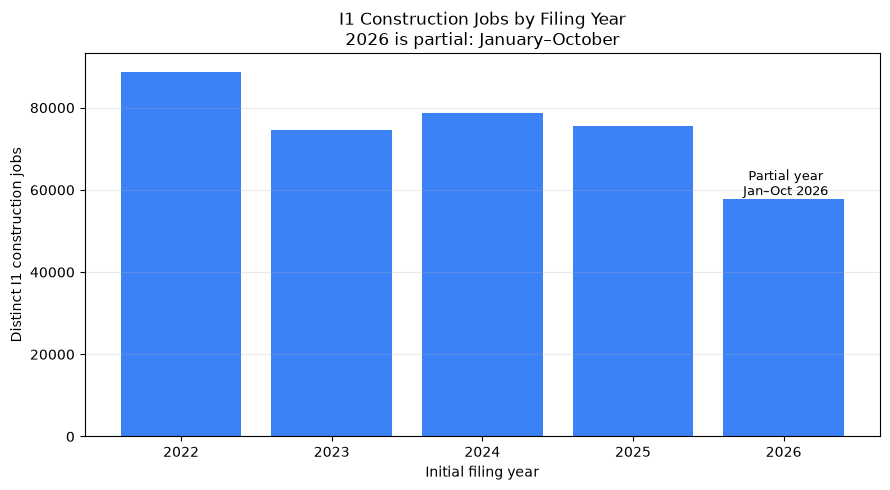

In [8]:
jobs_by_year = (
    reloaded.groupby("year", observed=True)["housing_job_count"]
    .sum()
    .reindex(range(2022, 2027), fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(jobs_by_year.index.astype(str), jobs_by_year.values, color="#3B82F6")
ax.set_title("I1 Construction Jobs by Filing Year\n2026 is partial: January–October")
ax.set_xlabel("Initial filing year")
ax.set_ylabel("Distinct I1 construction jobs")
ax.grid(axis="y", alpha=0.25)
ax.text(
    4,
    jobs_by_year.loc[2026],
    " Partial year\n Jan–Oct 2026",
    va="bottom",
    ha="center",
    fontsize=9,
)
plt.tight_layout()
plt.show()

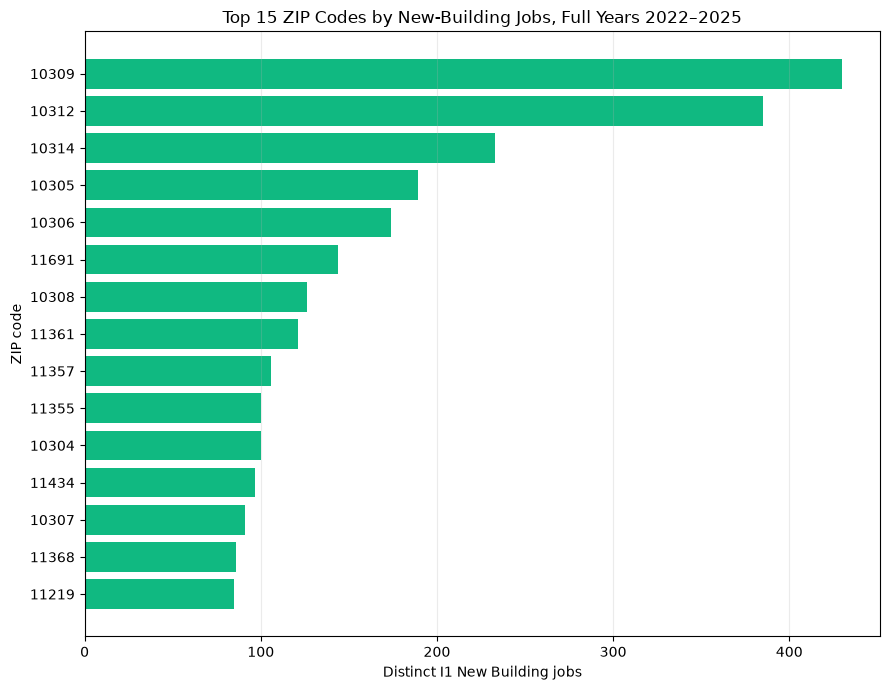

In [9]:
top_15_new_building_zips = (
    reloaded.loc[reloaded["year"].between(2022, 2025)]
    .groupby("zip_code", observed=True)["new_building_count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(
    top_15_new_building_zips.index.astype(str),
    top_15_new_building_zips.values,
    color="#10B981",
)
ax.set_title("Top 15 ZIP Codes by New-Building Jobs, Full Years 2022–2025")
ax.set_xlabel("Distinct I1 New Building jobs")
ax.set_ylabel("ZIP code")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

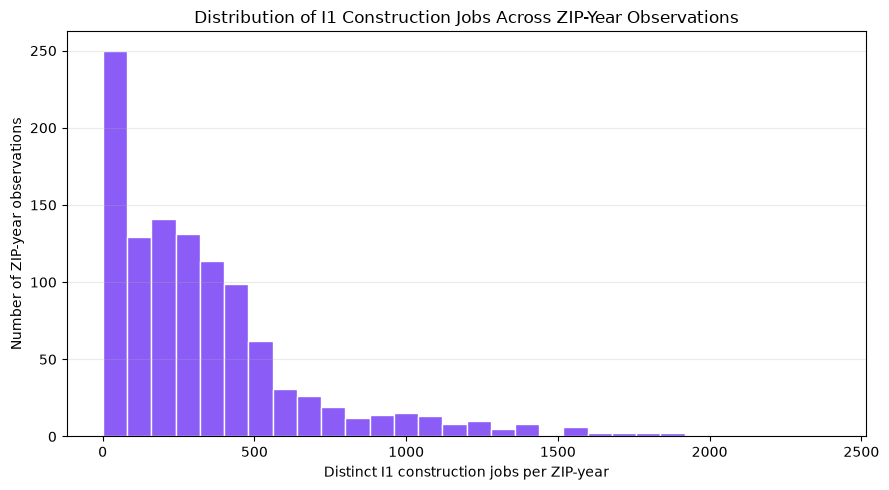

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(reloaded["housing_job_count"], bins=30, color="#8B5CF6", edgecolor="white")
ax.set_title("Distribution of I1 Construction Jobs Across ZIP-Year Observations")
ax.set_xlabel("Distinct I1 construction jobs per ZIP-year")
ax.set_ylabel("Number of ZIP-year observations")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Limitations

- The 2026 values cover January through October and are not directly comparable with complete calendar years without acknowledging partial coverage.
- The measures represent filing activity, not completed construction or occupancy.
- Housing activity and collision patterns observed at the same ZIP-year grain do not establish causation.
- ZIP-year aggregation cannot identify a direct relationship between an individual building project and an individual collision.
- Jobs whose I1 filing falls outside the analysis window are excluded even when later filings occur during 2022–2026.

## Handoff to Issa

The following executed summary documents the local integration artifact. Because `data/` is Git-ignored, the CSV must be transferred separately or regenerated by running this notebook; committing the notebook alone does not deliver the data file.

In [11]:
handoff_dtypes = pd.Series(
    {column: str(reloaded[column].dtype) for column in output_columns},
    name="Reloaded dtype",
)
display(handoff_dtypes.to_frame())

display(
    Markdown(
        f"**Validated handoff:** `{OUTPUT.as_posix()}` contains "
        f"**{len(reloaded):,} rows**, **{reloaded['zip_code'].nunique():,} unique "
        f"ZIP codes**, and years **{reloaded['year'].min()}–{reloaded['year'].max()}**. "
        "It has exactly the required nine columns, one row per ZIP-year, and all "
        "pre-export and reload assertions passed."
    )
)
print("Final notebook validation result: PASS")

,Reloaded dtype
zip_code,string
year,int64
borough,string
housing_job_count,int64
new_building_count,int64
alteration_job_count,int64
demolition_job_count,int64
proposed_dwelling_units_new_buildings,int64
is_partial_year,boolean


**Validated handoff:** `data/housing_zip_year.csv.gz` contains **1,104 rows**, **224 unique ZIP codes**, and years **2022–2026**. It has exactly the required nine columns, one row per ZIP-year, and all pre-export and reload assertions passed.

Final notebook validation result: PASS


## Prompts used

The implementation request and how its output was used are documented in the shared root-level `AI_PROMPTS.txt` file using the team's required chronological format.